<a href="https://colab.research.google.com/github/hwasun-zip/Cookie_Cats/blob/main/CookieCats.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cookie_Cats: A/B 테스트 결과 검증과 리텐션 개선 실험 설계

관문을 레벨 30에서 40으로 늦춘 모바일 게임 A/B 테스트(유저 90,189명)를 분석한다.
결과를 그대로 믿지 않고 실험이 제대로 배정됐는지부터 확인하고, 리텐션과 관련된 유저 행동을 찾아 이를 검증할 후속 실험을 설계한다.

- 데이터: Kaggle Cookie Cats A/B 테스트 (유저 90,189명)
- 방법: SRM 검정, 민감도 분석, 카이제곱 검정, 부트스트랩, 검정력 분석

## 1단계: 데이터 준비

In [ ]:
# 1) kaggle.json 업로드
from google.colab import files
files.upload()

# 2) Kaggle API 설정
import os
os.makedirs("/root/.kaggle", exist_ok=True)
!cp kaggle.json /root/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json
!pip install kaggle -q

# 3) Cookie Cats 데이터셋 다운로드 + 압축 해제
!kaggle datasets download -d yufengsui/mobile-games-ab-testing
!unzip -o mobile-games-ab-testing.zip

print("✅ 다운로드 완료")

Saving kaggle (1).json to kaggle (1).json
cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/yufengsui/mobile-games-ab-testing
License(s): unknown
100% 490k/490k [00:00<00:00, 116MB/s]

Archive:  mobile-games-ab-testing.zip
  inflating: cookie_cats.csv         
✅ 다운로드 완료


In [ ]:
import os
print([f for f in os.listdir() if f.endswith(".csv")])

['cookie_cats.csv']


In [ ]:
# 데이터 로드 + 구조 확인
import pandas as pd

df = pd.read_csv("cookie_cats.csv")
print("행 수:", len(df))
print("컬럼:", df.columns.tolist())
df.head()

행 수: 90189
컬럼: ['userid', 'version', 'sum_gamerounds', 'retention_1', 'retention_7']


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [ ]:
# A/B 그룹 크기 확인 (두 그룹이 비슷해야 공정한 실험)
print(df["version"].value_counts())

version
gate_40    45489
gate_30    44700
Name: count, dtype: int64


## 2단계: 실험 품질 검증 (SRM)

In [ ]:
# SRM(Sample Ratio Mismatch) 검정
# 50:50으로 배정했다면, 실제 인원 차이가 우연으로 설명되는 수준인지 확인
from scipy import stats

counts = df["version"].value_counts().sort_index()
n = counts.sum()
chi2, p = stats.chisquare(counts.values, f_exp=[n / 2, n / 2])

print(counts)
print(f"\ngate_40 비중: {counts['gate_40'] / n * 100:.2f}% (기대값 50%)")
print(f"SRM 카이제곱 검정: chi2 = {chi2:.2f}, p-value = {p:.4f}")

version
gate_30    44700
gate_40    45489
Name: count, dtype: int64

gate_40 비중: 50.44% (기대값 50%)
SRM 카이제곱 검정: chi2 = 6.90, p-value = 0.0086


## 3단계: SRM이 결론을 뒤집을 수 있을까 (민감도 분석)

In [ ]:
# 민감도 분석: SRM이 결론을 뒤집을 수 있을까?
# 가장 보수적인 가정: gate_30에서 빠진 789명이 전부 D+7 이탈자였다면?
missing = counts["gate_40"] - counts["gate_30"]

r30 = df.loc[df["version"] == "gate_30", "retention_7"]
r40 = df.loc[df["version"] == "gate_40", "retention_7"]

r30_worst = r30.sum() / (len(r30) + missing)
table = [
    [r30.sum(), len(r30) + missing - r30.sum()],
    [r40.sum(), len(r40) - r40.sum()],
]
chi2_w, p_w, _, _ = stats.chi2_contingency(table)

print(f"[원래]      gate_30 D+7 {r30.mean()*100:.2f}% vs gate_40 {r40.mean()*100:.2f}%  → 차이 {(r30.mean()-r40.mean())*100:.2f}%p")
print(f"[최악 가정] gate_30 D+7 {r30_worst*100:.2f}% vs gate_40 {r40.mean()*100:.2f}%  → 차이 {(r30_worst-r40.mean())*100:.2f}%p")
print(f"[최악 가정] 카이제곱 p-value = {p_w:.4f}")

[원래]      gate_30 D+7 19.02% vs gate_40 18.20%  → 차이 0.82%p
[최악 가정] gate_30 D+7 18.69% vs gate_40 18.20%  → 차이 0.49%p
[최악 가정] 카이제곱 p-value = 0.0577


## 4단계: 리텐션 기본 지표와 A/B 비교

In [ ]:
# 전체 리텐션율 (게임의 기본 건강도)
print("전체 D+1 리텐션:", round(df["retention_1"].mean()*100, 1), "%")
print("전체 D+7 리텐션:", round(df["retention_7"].mean()*100, 1), "%")

전체 D+1 리텐션: 44.5 %
전체 D+7 리텐션: 18.6 %


In [ ]:
# 게이트 위치별(A/B) 리텐션 비교
# "관문을 레벨30에 두느냐 40에 두느냐"가 리텐션에 영향을 줄까?

ab = df.groupby("version")[["retention_1", "retention_7"]].mean() * 100
ab = ab.round(2)
print(ab)

         retention_1  retention_7
version                          
gate_30        44.82        19.02
gate_40        44.23        18.20


In [ ]:
# 플레이 라운드 수 분포 (이탈 파악의 기초)
print(df["sum_gamerounds"].describe())
print("\n설치 후 한 판도 안 한 유저 비율:",
      round((df["sum_gamerounds"] == 0).mean()*100, 1), "%")

count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64

설치 후 한 판도 안 한 유저 비율: 4.4 %


In [ ]:
# (다음 단계에서 재사용)
df.to_csv("cookie_cats_clean.csv", index=False)
print("💾 저장 완료")

💾 저장 완료


## 5단계: A/B 통계 검정 (부트스트랩, 카이제곱)

In [ ]:
# A/B 리텐션 차이 통계 검정
# 한글 폰트 (그래프용)
!apt-get install -y fonts-nanum -qq
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
path = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
fm.fontManager.addfont(path)
plt.rcParams["font.family"] = fm.FontProperties(fname=path).get_name()
plt.rcParams["axes.unicode_minus"] = False
print("폰트 준비 완료")

Selecting previously unselected package fonts-nanum.
(Reading database ... 122807 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Setting up fonts-nanum (20200506-1) ...
Processing triggers for fontconfig (2.15.0-1.1ubuntu2) ...
폰트 준비 완료


In [ ]:
#   부트스트랩 검정 (D+7 리텐션)
#   데이터를 9만 명 풀에서 '복원추출'로 1만 번 다시 뽑아
#   매번 gate_30 - gate_40 리텐션 차이를 계산
#   → "gate_30이 더 높은" 경우가 몇 %인지 = 신뢰도
import numpy as np

g30 = df[df["version"] == "gate_30"]["retention_7"].values.astype(float)
g40 = df[df["version"] == "gate_40"]["retention_7"].values.astype(float)

np.random.seed(42)
diffs = []
for _ in range(10000):
    b30 = np.random.choice(g30, size=len(g30), replace=True).mean()
    b40 = np.random.choice(g40, size=len(g40), replace=True).mean()
    diffs.append((b30 - b40) * 100)   # %p 단위
diffs = np.array(diffs)

prob = (diffs > 0).mean() * 100
print(f"gate_30의 D+7 리텐션이 gate_40보다 높을 확률: {prob:.1f}%")
print(f"평균 차이: {diffs.mean():.2f}%p (95% 구간: "
      f"{np.percentile(diffs,2.5):.2f} ~ {np.percentile(diffs,97.5):.2f}%p)")

gate_30의 D+7 리텐션이 gate_40보다 높을 확률: 99.9%
평균 차이: 0.82%p (95% 구간: 0.32 ~ 1.32%p)


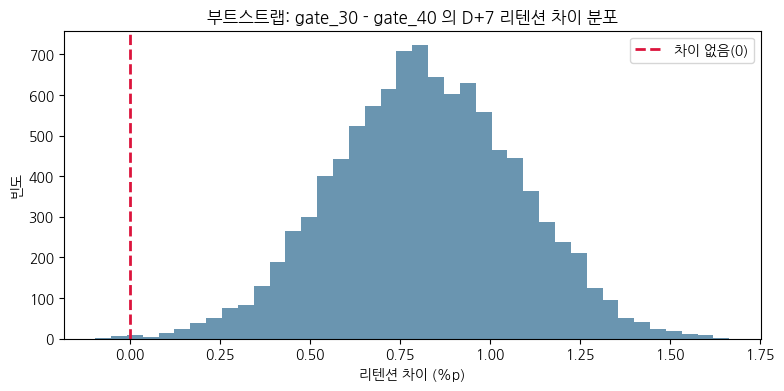

In [ ]:
# 부트스트랩 분포 시각화
plt.figure(figsize=(9, 4))
plt.hist(diffs, bins=40, color="#457b9d", alpha=0.8)
plt.axvline(0, color="crimson", linestyle="--", linewidth=2, label="차이 없음(0)")
plt.title("부트스트랩: gate_30 - gate_40 의 D+7 리텐션 차이 분포")
plt.xlabel("리텐션 차이 (%p)")
plt.ylabel("빈도")
plt.legend()
plt.savefig("retention_bootstrap.png", dpi=150, bbox_inches="tight")
plt.show()
# 해석: 분포가 대부분 0보다 오른쪽에 있으면
# "gate_30이 더 높다"가 우연이 아니라는 뜻.

In [ ]:
# 교차검증 - 카이제곱 검정 (D+1, D+7)
# 부트스트랩과 별개로 전통적 통계 검정으로도 확인
from scipy import stats
import pandas as pd

for col in ["retention_1", "retention_7"]:
    ct = pd.crosstab(df["version"], df[col])
    chi2, p, _, _ = stats.chi2_contingency(ct)
    sig = "유의미 ✅" if p < 0.05 else "유의미하지 않음 ❌"
    print(f"{col}: p-value = {p:.4f} → {sig}")

retention_1: p-value = 0.0755 → 유의미하지 않음 ❌
retention_7: p-value = 0.0016 → 유의미 ✅


## 6단계: 플레이량과 리텐션의 관계

In [ ]:
# 세그먼트, 이탈 구간 분석
# 폰트
!apt-get install -y fonts-nanum -qq
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
path = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
fm.fontManager.addfont(path)
plt.rcParams["font.family"] = fm.FontProperties(fname=path).get_name()
plt.rcParams["axes.unicode_minus"] = False
print("폰트 준비 완료")

폰트 준비 완료


In [ ]:
# 플레이량 구간별 리텐션
# 유저를 플레이 라운드 수로 그룹핑 → 각 그룹의 D1/D7 리텐션 비교

import pandas as pd

bins   = [-1, 0, 5, 15, 50, 100, df["sum_gamerounds"].max()]
labels = ["0판", "1~5판", "6~15판", "16~50판", "51~100판", "100판+"]
df["round_group"] = pd.cut(df["sum_gamerounds"], bins=bins, labels=labels)

seg = df.groupby("round_group").agg(
    유저수=("userid", "count"),
    D1리텐션=("retention_1", "mean"),
    D7리텐션=("retention_7", "mean"),
)
seg["유저비율(%)"] = (seg["유저수"] / len(df) * 100).round(1)
seg["D1리텐션(%)"] = (seg["D1리텐션"] * 100).round(1)
seg["D7리텐션(%)"] = (seg["D7리텐션"] * 100).round(1)
print(seg[["유저수", "유저비율(%)", "D1리텐션(%)", "D7리텐션(%)"]])

               유저수  유저비율(%)  D1리텐션(%)  D7리텐션(%)
round_group                                    
0판            3994      4.4       2.2       0.7
1~5판         20723     23.0       7.7       1.4
6~15판        19055     21.1      26.5       3.9
16~50판       23605     26.2      58.8      13.5
51~100판      10427     11.6      80.4      35.6
100판+        12385     13.7      90.0      71.3


/tmp/ipykernel_398/737755830.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  seg = df.groupby("round_group").agg(


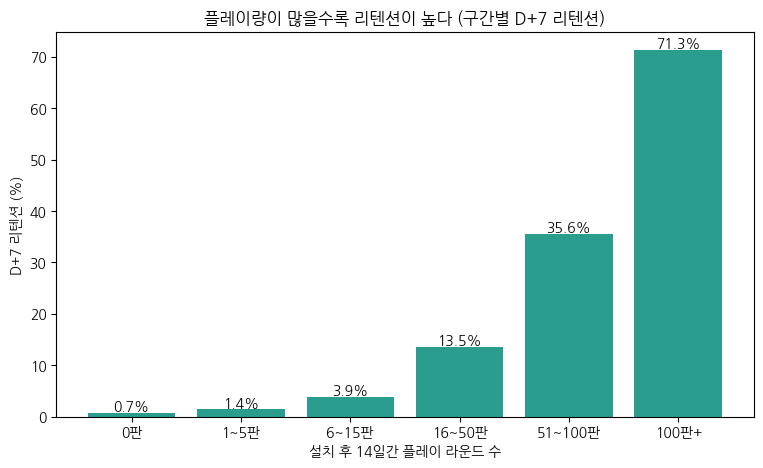

In [ ]:
# 시각화 - 플레이량 구간별 D+7 리텐션

plt.figure(figsize=(9, 5))
bars = plt.bar(seg.index.astype(str), seg["D7리텐션(%)"], color="#2a9d8f")
plt.title("플레이량이 많을수록 리텐션이 높다 (구간별 D+7 리텐션)")
plt.ylabel("D+7 리텐션 (%)")
plt.xlabel("설치 후 14일간 플레이 라운드 수")
for b, v in zip(bars, seg["D7리텐션(%)"]):
    plt.text(b.get_x() + b.get_width()/2, v + 0.5, f"{v}%", ha="center", fontweight="bold")
plt.savefig("retention_by_engagement.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# 초반 저참여 vs 그 이상
# "몇 판을 넘기느냐"가 리텐션을 가르는 분기점을 보여줌

low  = df[df["sum_gamerounds"] <= 5]
high = df[df["sum_gamerounds"] > 5]

print(f"◆ 5판 이하 유저: {len(low)}명 (전체의 {len(low)/len(df)*100:.1f}%)")
print(f"   └ D+7 리텐션: {low['retention_7'].mean()*100:.1f}%")
print(f"◆ 6판 이상 유저: {len(high)}명 (전체의 {len(high)/len(df)*100:.1f}%)")
print(f"   └ D+7 리텐션: {high['retention_7'].mean()*100:.1f}%")
print(f"\n→ 초반 5판을 넘기면 리텐션이 약 "
      f"{high['retention_7'].mean()/low['retention_7'].mean():.1f}배 높아짐")

◆ 5판 이하 유저: 24717명 (전체의 27.4%)
   └ D+7 리텐션: 1.3%
◆ 6판 이상 유저: 65472명 (전체의 72.6%)
   └ D+7 리텐션: 25.2%

→ 초반 5판을 넘기면 리텐션이 약 19.9배 높아짐


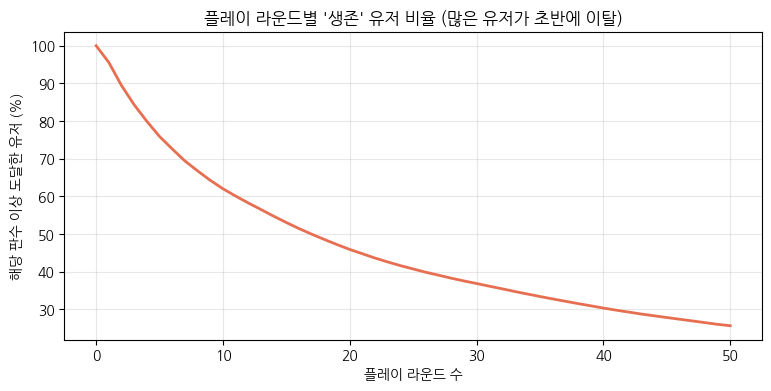

In [ ]:
# 누적 이탈 곡선 - 몇 판까지 왔는지 분포

import numpy as np
rounds = df["sum_gamerounds"]
xs = range(0, 51)
survival = [ (rounds >= x).mean()*100 for x in xs ]   # x판 이상 도달한 유저 비율
plt.figure(figsize=(9, 4))
plt.plot(list(xs), survival, color="#e76f51", linewidth=2)
plt.title("플레이 라운드별 '생존' 유저 비율 (많은 유저가 초반에 이탈)")
plt.xlabel("플레이 라운드 수")
plt.ylabel("해당 판수 이상 도달한 유저 (%)")
plt.grid(alpha=0.3)
plt.savefig("survival_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
from google.colab import files
for f in ["retention_bootstrap.png", "retention_by_engagement.png", "survival_curve.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7단계: 후속 실험 설계 (표본 크기 계산)

In [ ]:
# 후속 실험 설계: "초반 5판 마일스톤 보상"이 D+7 리텐션을 올리는가?
# 5판 이상 유저의 리텐션이 높은 건 상관관계일 뿐(남은 유저가 많이 플레이했을 수도 있음)
# → 인과를 확인하려면 무작위 실험이 필요. 그 실험에 필요한 표본 수를 계산
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

base = df["retention_7"].mean()   # 현재 D+7 리텐션 (기준선)
power_analysis = NormalIndPower()

rows = []
for mde in [0.005, 0.01, 0.02]:   # 검출하고 싶은 최소 효과 (절대 %p)
    h = proportion_effectsize(base + mde, base)
    n = power_analysis.solve_power(effect_size=h, alpha=0.05, power=0.8, ratio=1.0)
    n = int(np.ceil(n))
    rows.append([f"+{mde*100:.1f}%p", f"{base*100:.1f}% → {(base+mde)*100:.1f}%", n, n * 2])

design = pd.DataFrame(rows, columns=["최소 검출 효과", "D+7 리텐션", "그룹당 필요 유저", "총 필요 유저"])
print(f"기준 D+7 리텐션: {base*100:.2f}%  |  유의수준 5%, 검정력 80%, 50:50 배정\n")
print(design.to_string(index=False))

기준 D+7 리텐션: 18.61%  |  유의수준 5%, 검정력 80%, 50:50 배정

최소 검출 효과       D+7 리텐션  그룹당 필요 유저  총 필요 유저
  +0.5%p 18.6% → 19.1%      96072   192144
  +1.0%p 18.6% → 19.6%      24259    48518
  +2.0%p 18.6% → 20.6%       6183    12366


## 후속 실험 설계: 초반 5판 마일스톤 보상

**배경**: 5판 이상 플레이한 유저의 D+7 리텐션은 25.2%로, 5판 이하(1.3%)보다 크게 높았다. 하지만 이는 상관관계다. 리텐션이 높은 유저가 결과적으로 많이 플레이했을 수도 있으므로, 5판 돌파를 유도하면 리텐션이 오르는지는 실험으로 확인해야 한다.

| 항목 | 설계 |
|---|---|
| 가설 | 초반 5판 돌파 시 보상을 주면 D+7 리텐션이 오른다 |
| 대상 | 신규 설치 유저 |
| 배정 | 설치 시점에 50:50 무작위 배정 (대조군: 보상 없음, 처치군: 5판 돌파 보상) |
| 핵심 지표 | D+7 리텐션 |
| 확인 지표 | 5판 돌파율 (보상이 실제로 행동을 바꿨는지 확인) |
| 가드레일 지표 | D+1 리텐션, 결제 전환율 (보상이 다른 지표를 해치지 않는지 확인) |
| 최소 검출 효과 | +1.0%p (18.6% → 19.6%) |
| 표본 크기 | 그룹당 24,259명, 총 48,518명 (유의수준 5%, 검정력 80%) |

**분석 전 확인할 것**
- SRM 검정: 이번 게이트 실험에서 배정 비율 불균형(p = 0.0086)이 발견되었으므로, 결과를 보기 전에 배정 비율부터 확인한다
- 5판 돌파율이 처치군에서 올랐는지 먼저 확인한다. 돌파율이 오르지 않았다면 리텐션 차이를 보상 효과로 해석하지 않는다

**판단 기준**
- D+7 리텐션이 유의하게 오르고 가드레일 지표가 유지되면 전체 적용
- 5판 돌파율은 올랐지만 D+7 리텐션 개선이 확인되지 않으면, 가설을 뒷받침할 근거가 부족한 것으로 판단하고 다른 개입을 검토

## 결과 요약

| 질문 | 결과 |
|---|---|
| 관문을 늦추면 리텐션이 오르는가 | 기각. D+7 리텐션이 오히려 0.82%p 낮음 (카이제곱 p = 0.0016, 부트스트랩 99.9%) |
| 그 결과를 믿을 수 있는가 | 배정 비율 이상 발견(SRM, p = 0.0086). 빠진 789명이 모두 이탈자라는 최악의 가정에서 차이는 0.49%p로 방향은 유지됐지만 유의성이 약해짐(p = 0.058). 확정 전 원인 확인과 재실험 권장 |
| 초반 플레이를 늘리면 리텐션이 오르는가 | 보류. 5판 이하 1.3% vs 6판 이상 25.2%지만, 판수가 14일 누적값이라 상관관계로 판단 |
| 다음에 무엇을 실험할까 | '5판 마일스톤 보상' 실험 설계. +1.0%p 검출에 총 48,518명 필요(검정력 80%) |

### 한계
- 공개 데이터라 SRM의 원인을 직접 확인할 수 없어, 민감도 분석으로 결론의 범위만 확인했다
- 후속 실험은 설계까지만 진행했으며, 실제 실행 결과는 아니다